In [1]:
print("Food Spoilage Prediction Project")
print("Python environment is ready!")
print("Let's build our ML model!")

Food Spoilage Prediction Project
Python environment is ready!
Let's build our ML model!


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn

print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("Scikit-learn version:", sklearn.__version__)

print("\nAll basic ML libraries are ready!")

Pandas version: 2.2.3
NumPy version: 2.1.3
Scikit-learn version: 1.6.1

All basic ML libraries are ready!


In [3]:
from google.colab import files

uploaded = files.upload()

print("Uploaded files:", list(uploaded.keys()))

Saving FoodSpoilage.MWX to FoodSpoilage.MWX
Uploaded files: ['FoodSpoilage.MWX']


In [4]:
import json
import zipfile
import pandas as pd
from io import BytesIO

filename = "FoodSpoilage.MWX"

with zipfile.ZipFile(BytesIO(uploaded[filename])) as z:
    print("Files inside worksheet:", z.namelist())

    sheet_files = [
        name for name in z.namelist()
        if name.endswith("sheet.json")
    ]

    if not sheet_files:
        raise ValueError(
            "No sheet.json found. We need another conversion method."
        )

    sheet = json.loads(z.read(sheet_files[0]))
    data = {
        column["name"]: column["values"]
        for column in sheet["columns"]
    }

    df = pd.DataFrame(data).replace("*", pd.NA)

print("\nDataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst five rows:")
display(df.head())

print("\nData types and missing values:")
df.info()

Files inside worksheet: ['/', '/sheet_metadata_20.json', '/sheets/', '/sheets/0/', '/sheets/0/sheet.json']


KeyError: 'columns'

In [5]:
import zipfile
import json
from io import BytesIO

filename = "FoodSpoilage.MWX"

with zipfile.ZipFile(BytesIO(uploaded[filename])) as z:
    print("Files inside the worksheet:\n")
    for name in z.namelist():
        print(name)

    print("\n--- Inspecting JSON structure ---")

    json_files = [
        name for name in z.namelist()
        if name.lower().endswith(".json")
    ]

    for name in json_files[:3]:
        print(f"\nFile: {name}")

        content = json.loads(z.read(name))

        if isinstance(content, dict):
            print("Top-level keys:", list(content.keys()))
        else:
            print("Top-level type:", type(content).__name__)

        print("Preview:")
        print(json.dumps(content, indent=2)[:2000])

Files inside the worksheet:

/
/sheet_metadata_20.json
/sheets/
/sheets/0/
/sheets/0/sheet.json

--- Inspecting JSON structure ---

File: /sheet_metadata_20.json
Top-level keys: ['Version', 'Worksheet']
Preview:
{
  "Version": 20200604.0,
  "Worksheet": {
    "Name": "Worksheet 1",
    "Uri": "/sheets/0/sheet",
    "Comments": "",
    "Creator": "",
    "Date": "",
    "ExtraInformation": {}
  }
}

File: /sheets/0/sheet.json
Top-level keys: ['Data', 'Word_DEP', 'MaxRows_DEP', 'MaxColumns_DEP', 'MaxConstants_DEP', 'MaxMatrices_DEP', 'CreationDate', 'LastSavedDate', 'Version', 'SaveAsVersion', 'Creator', 'Date', 'Comment', 'OSVersion_DEP', 'CodePage_DEP', 'CreatedDate', 'SavedDate', 'Class_Version']
Preview:
{
  "Data": {
    "ClassId": 1,
    "Type_DEP": 1263685463,
    "IOtype_DEP": 1,
    "Name": "",
    "PrivateTitle": "Worksheet 1",
    "HTMLOptions": {
      "ClassId": 0,
      "Title": ""
    },
    "WorksheetViewData": {
      "ClassId": 0,
      "PrintGrid": true,
      "PrintCo

In [6]:
import zipfile
import json
from io import BytesIO

filename = "FoodSpoilage.MWX"

with zipfile.ZipFile(BytesIO(uploaded[filename])) as z:
    print("Files inside the worksheet:\n")
    for name in z.namelist():
        print(name)

    print("\n--- Inspecting JSON structure ---")

    json_files = [
        name for name in z.namelist()
        if name.lower().endswith(".json")
    ]

    for name in json_files[:3]:
        print(f"\nFile: {name}")

        content = json.loads(z.read(name))

        if isinstance(content, dict):
            print("Top-level keys:", list(content.keys()))
        else:
            print("Top-level type:", type(content).__name__)

        print("Preview:")
        print(json.dumps(content, indent=2)[:2000])

Files inside the worksheet:

/
/sheet_metadata_20.json
/sheets/
/sheets/0/
/sheets/0/sheet.json

--- Inspecting JSON structure ---

File: /sheet_metadata_20.json
Top-level keys: ['Version', 'Worksheet']
Preview:
{
  "Version": 20200604.0,
  "Worksheet": {
    "Name": "Worksheet 1",
    "Uri": "/sheets/0/sheet",
    "Comments": "",
    "Creator": "",
    "Date": "",
    "ExtraInformation": {}
  }
}

File: /sheets/0/sheet.json
Top-level keys: ['Data', 'Word_DEP', 'MaxRows_DEP', 'MaxColumns_DEP', 'MaxConstants_DEP', 'MaxMatrices_DEP', 'CreationDate', 'LastSavedDate', 'Version', 'SaveAsVersion', 'Creator', 'Date', 'Comment', 'OSVersion_DEP', 'CodePage_DEP', 'CreatedDate', 'SavedDate', 'Class_Version']
Preview:
{
  "Data": {
    "ClassId": 1,
    "Type_DEP": 1263685463,
    "IOtype_DEP": 1,
    "Name": "",
    "PrivateTitle": "Worksheet 1",
    "HTMLOptions": {
      "ClassId": 0,
      "Title": ""
    },
    "WorksheetViewData": {
      "ClassId": 0,
      "PrintGrid": true,
      "PrintCo

In [7]:
import json
import zipfile
from io import BytesIO

with zipfile.ZipFile(BytesIO(uploaded["FoodSpoilage.MWX"])) as z:
    sheet = json.loads(z.read("sheets/0/sheet.json"))

data = sheet["Data"]

print("Worksheet keys:")
print(list(data.keys()))

columns = data["Columns"]

print("\nNumber of columns:", len(columns))

for i, col in enumerate(columns):
    body = col.get("WorksheetVarBody", {})
    print(f"\n--- Column {i + 1} ---")
    print("Name:", body.get("Name"))
    print("Available keys:", list(body.keys()))
    print(json.dumps(body.get("VarData", {}), indent=2)[:1200])

KeyError: "There is no item named 'sheets/0/sheet.json' in the archive"

In [8]:
import json
import zipfile
from io import BytesIO

filename = next(
    name for name in uploaded
    if name.lower().endswith(".mwx")
)

with zipfile.ZipFile(BytesIO(uploaded[filename])) as z:

    # Find the sheet file regardless of leading slash
    sheet_path = next(
        name for name in z.namelist()
        if name.lower().endswith("sheet.json")
    )

    print("Reading worksheet:", repr(sheet_path))

    sheet = json.loads(z.read(sheet_path))

data = sheet["Data"]
columns = data["Columns"]

print("\nNumber of columns:", len(columns))

for i, col in enumerate(columns):
    body = col.get("WorksheetVarBody", {})
    print(f"\nColumn {i + 1}: {body.get('Name')}")
    print("Available keys:", list(body.keys()))
    print("Variable data preview:")
    print(json.dumps(body.get("VarData", {}), indent=2)[:700])

Reading worksheet: '/sheets/0/sheet.json'

Number of columns: 10

Column 1: StdOrder
Available keys: ['ClassId', 'Name', 'Desc', 'Format', 'VarData', 'Ordering', 'FormatType', 'GeneralVarFmt', 'Available', 'Compressed', 'HasChanged', 'FormatDirty', 'Class_Version']
Variable data preview:
{
  "ClassId": 439,
  "VariableType": 3,
  "Data": 1,
  "VarDataBody": {
    "ClassId": 447,
    "CellCt": 16,
    "ColCt": 1,
    "CharCt": 0,
    "HasNumericData": true,
    "NumericData": [
      1.0,
      2.0,
      3.0,
      4.0,
      5.0,
      6.0,
      7.0,
      8.0,
      9.0,
      10.0,
      11.0,
      12.0,
      13.0,
      14.0,
      15.0,
      16.0
    ],
    "HasTextData": false
  },
  "Locked": false,
  "Class_Version": [
    2
  ]
}

Column 2: RunOrder
Available keys: ['ClassId', 'Name', 'Desc', 'Format', 'VarData', 'Ordering', 'FormatType', 'GeneralVarFmt', 'Available', 'Compressed', 'HasChanged', 'FormatDirty', 'Class_Version']
Variable data preview:
{
  "ClassId": 439,
  "

In [9]:
import json
import zipfile
import pandas as pd
from io import BytesIO

filename = next(
    name for name in uploaded
    if name.lower().endswith(".mwx")
)

with zipfile.ZipFile(BytesIO(uploaded[filename])) as z:
    sheet_path = next(
        name for name in z.namelist()
        if name.lower().endswith("sheet.json")
    )
    sheet = json.loads(z.read(sheet_path))

columns = sheet["Data"]["Columns"]
data = {}

for col in columns:
    body = col["WorksheetVarBody"]
    name = body["Name"]
    var_body = body["VarData"]["VarDataBody"]

    if var_body.get("HasNumericData"):
        values = var_body["NumericData"]
    elif var_body.get("HasTextData"):
        values = var_body["TextData"]
    else:
        values = [None] * var_body.get("CellCt", 0)

    data[name] = values

df = pd.DataFrame(data)

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

display(df.head(10))

Dataset loaded successfully!
Rows: 16
Columns: 10


,StdOrder,RunOrder,CenterPt,Blocks,Preservative,VacuumPress,ContaminationLevel,CoolTemp,Spoilage,Containers
0,1.0,7.0,1.0,1.0,Formula1,5.0,5.0,10.0,20.0,500.0
1,2.0,6.0,1.0,1.0,Formula2,5.0,5.0,10.0,32.0,500.0
2,3.0,9.0,1.0,1.0,Formula1,25.0,5.0,10.0,29.0,500.0
3,4.0,14.0,1.0,1.0,Formula2,25.0,5.0,10.0,42.0,500.0
4,5.0,15.0,1.0,1.0,Formula1,5.0,50.0,10.0,24.0,500.0
5,6.0,2.0,1.0,1.0,Formula2,5.0,50.0,10.0,40.0,500.0
6,7.0,11.0,1.0,1.0,Formula1,25.0,50.0,10.0,32.0,500.0
7,8.0,5.0,1.0,1.0,Formula2,25.0,50.0,10.0,45.0,500.0
8,9.0,13.0,1.0,1.0,Formula1,5.0,5.0,20.0,18.0,500.0
9,10.0,10.0,1.0,1.0,Formula2,5.0,5.0,20.0,24.0,500.0


In [10]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nSummary statistics:")
display(df.describe(include="all"))

print("\nMissing values per column:")
print(df.isna().sum())

Column names:
['StdOrder', 'RunOrder', 'CenterPt', 'Blocks', 'Preservative', 'VacuumPress', 'ContaminationLevel', 'CoolTemp', 'Spoilage', 'Containers']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16 entries, 0 to 15
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   StdOrder            16 non-null     float64
 1   RunOrder            16 non-null     float64
 2   CenterPt            16 non-null     float64
 3   Blocks              16 non-null     float64
 4   Preservative        16 non-null     object 
 5   VacuumPress         16 non-null     float64
 6   ContaminationLevel  16 non-null     float64
 7   CoolTemp            16 non-null     float64
 8   Spoilage            16 non-null     float64
 9   Containers          16 non-null     float64
dtypes: float64(9), object(1)
memory usage: 1.4+ KB

Summary statistics:


,StdOrder,RunOrder,CenterPt,Blocks,Preservative,VacuumPress,ContaminationLevel,CoolTemp,Spoilage,Containers
count,16.000000,16.000000,16.0,16.0,16,16.000000,16.0000,16.000000,16.000000,16.00000
unique,NaN,NaN,NaN,NaN,2,NaN,NaN,NaN,NaN,NaN
top,NaN,NaN,NaN,NaN,Formula1,NaN,NaN,NaN,NaN,NaN
freq,NaN,NaN,NaN,NaN,8,NaN,NaN,NaN,NaN,NaN
mean,8.500000,8.500000,1.0,1.0,NaN,15.000000,27.5000,15.000000,31.625000,499.25000
std,4.760952,4.760952,0.0,0.0,NaN,10.327956,23.2379,5.163978,9.769852,1.65328
min,1.000000,1.000000,1.0,1.0,NaN,5.000000,5.0000,10.000000,18.000000,495.00000
25%,4.750000,4.750000,1.0,1.0,NaN,5.000000,5.0000,10.000000,24.000000,500.00000
50%,8.500000,8.500000,1.0,1.0,NaN,15.000000,27.5000,15.000000,29.500000,500.00000
75%,12.250000,12.250000,1.0,1.0,NaN,25.000000,50.0000,20.000000,40.250000,500.00000



Missing values per column:
StdOrder              0
RunOrder              0
CenterPt              0
Blocks                0
Preservative          0
VacuumPress           0
ContaminationLevel    0
CoolTemp              0
Spoilage              0
Containers            0
dtype: int64


In [11]:
import json
import zipfile
import pandas as pd
from io import BytesIO

filename = next(
    name for name in uploaded
    if name.lower().endswith(".mwx")
)

with zipfile.ZipFile(BytesIO(uploaded[filename])) as z:
    sheet_path = next(
        name for name in z.namelist()
        if name.lower().endswith("sheet.json")
    )
    sheet = json.loads(z.read(sheet_path))

columns = sheet["Data"]["Columns"]
data = {}

for col in columns:
    body = col["WorksheetVarBody"]
    name = body["Name"]
    var_body = body["VarData"]["VarDataBody"]

    if var_body.get("HasNumericData"):
        values = var_body["NumericData"]
    elif var_body.get("HasTextData"):
        values = var_body["TextData"]
    else:
        values = [None] * var_body.get("CellCt", 0)

    data[name] = values

df = pd.DataFrame(data)

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

display(df.head(10))

Dataset loaded successfully!
Rows: 16
Columns: 10


,StdOrder,RunOrder,CenterPt,Blocks,Preservative,VacuumPress,ContaminationLevel,CoolTemp,Spoilage,Containers
0,1.0,7.0,1.0,1.0,Formula1,5.0,5.0,10.0,20.0,500.0
1,2.0,6.0,1.0,1.0,Formula2,5.0,5.0,10.0,32.0,500.0
2,3.0,9.0,1.0,1.0,Formula1,25.0,5.0,10.0,29.0,500.0
3,4.0,14.0,1.0,1.0,Formula2,25.0,5.0,10.0,42.0,500.0
4,5.0,15.0,1.0,1.0,Formula1,5.0,50.0,10.0,24.0,500.0
5,6.0,2.0,1.0,1.0,Formula2,5.0,50.0,10.0,40.0,500.0
6,7.0,11.0,1.0,1.0,Formula1,25.0,50.0,10.0,32.0,500.0
7,8.0,5.0,1.0,1.0,Formula2,25.0,50.0,10.0,45.0,500.0
8,9.0,13.0,1.0,1.0,Formula1,5.0,5.0,20.0,18.0,500.0
9,10.0,10.0,1.0,1.0,Formula2,5.0,5.0,20.0,24.0,500.0


In [12]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nSummary statistics:")
display(df.describe(include="all"))

print("\nMissing values:")
print(df.isna().sum())

Column names:
['StdOrder', 'RunOrder', 'CenterPt', 'Blocks', 'Preservative', 'VacuumPress', 'ContaminationLevel', 'CoolTemp', 'Spoilage', 'Containers']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16 entries, 0 to 15
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   StdOrder            16 non-null     float64
 1   RunOrder            16 non-null     float64
 2   CenterPt            16 non-null     float64
 3   Blocks              16 non-null     float64
 4   Preservative        16 non-null     object 
 5   VacuumPress         16 non-null     float64
 6   ContaminationLevel  16 non-null     float64
 7   CoolTemp            16 non-null     float64
 8   Spoilage            16 non-null     float64
 9   Containers          16 non-null     float64
dtypes: float64(9), object(1)
memory usage: 1.4+ KB

Summary statistics:


,StdOrder,RunOrder,CenterPt,Blocks,Preservative,VacuumPress,ContaminationLevel,CoolTemp,Spoilage,Containers
count,16.000000,16.000000,16.0,16.0,16,16.000000,16.0000,16.000000,16.000000,16.00000
unique,NaN,NaN,NaN,NaN,2,NaN,NaN,NaN,NaN,NaN
top,NaN,NaN,NaN,NaN,Formula1,NaN,NaN,NaN,NaN,NaN
freq,NaN,NaN,NaN,NaN,8,NaN,NaN,NaN,NaN,NaN
mean,8.500000,8.500000,1.0,1.0,NaN,15.000000,27.5000,15.000000,31.625000,499.25000
std,4.760952,4.760952,0.0,0.0,NaN,10.327956,23.2379,5.163978,9.769852,1.65328
min,1.000000,1.000000,1.0,1.0,NaN,5.000000,5.0000,10.000000,18.000000,495.00000
25%,4.750000,4.750000,1.0,1.0,NaN,5.000000,5.0000,10.000000,24.000000,500.00000
50%,8.500000,8.500000,1.0,1.0,NaN,15.000000,27.5000,15.000000,29.500000,500.00000
75%,12.250000,12.250000,1.0,1.0,NaN,25.000000,50.0000,20.000000,40.250000,500.00000



Missing values:
StdOrder              0
RunOrder              0
CenterPt              0
Blocks                0
Preservative          0
VacuumPress           0
ContaminationLevel    0
CoolTemp              0
Spoilage              0
Containers            0
dtype: int64


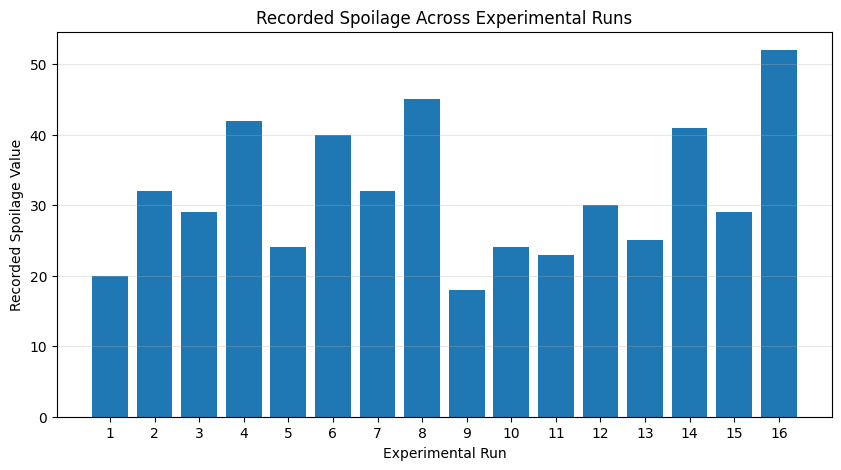

Average recorded spoilage by cooling temperature:


,CoolTemp,Spoilage
0,10.0,33.00
1,20.0,30.25


Average recorded spoilage by preservative:


,Preservative,Spoilage
0,Formula1,25.00
1,Formula2,38.25


In [13]:

import matplotlib.pyplot as plt

# Plot the recorded spoilage values for all 16 experimental runs
plt.figure(figsize=(10, 5))
plt.bar(range(1, len(df) + 1), df["Spoilage"])
plt.xlabel("Experimental Run")
plt.ylabel("Recorded Spoilage Value")
plt.title("Recorded Spoilage Across Experimental Runs")
plt.xticks(range(1, len(df) + 1))
plt.grid(axis="y", alpha=0.3)
plt.show()

# Compare spoilage across the recorded cooling temperatures
print("Average recorded spoilage by cooling temperature:")
display(
    df.groupby("CoolTemp")["Spoilage"]
      .mean()
      .reset_index()
)

# Compare spoilage across preservative formulas
print("Average recorded spoilage by preservative:")
display(
    df.groupby("Preservative")["Spoilage"]
      .mean()
      .reset_index()
)


In [14]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import LeaveOneOut, cross_val_predict
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Predict the recorded spoilage value using experimental factors
features = [
    "Preservative",
    "VacuumPress",
    "ContaminationLevel",
    "CoolTemp"
]

X = df[features]
y = df["Spoilage"]

# Convert the text-based preservative column into numeric features
preprocessor = ColumnTransformer(
    transformers=[
        ("preservative", OneHotEncoder(handle_unknown="ignore"),
         ["Preservative"]),
        ("numeric", "passthrough",
         ["VacuumPress", "ContaminationLevel", "CoolTemp"])
    ]
)

model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=100,
        max_depth=3,
        random_state=42
    ))
])

# Leave-one-out cross-validation: each row is tested while held out
# once, using the other 15 rows for training.
predictions = cross_val_predict(
    model, X, y, cv=LeaveOneOut()
)

mae = mean_absolute_error(y, predictions)
rmse = np.sqrt(mean_squared_error(y, predictions))
r2 = r2_score(y, predictions)

print("BASELINE MODEL: RANDOM FOREST REGRESSION")
print("-----------------------------------------")
print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
print(f"R² Score: {r2:.3f}")

# Compare actual and cross-validated predicted values
results = pd.DataFrame({
    "Actual Spoilage": y.to_numpy(),
    "Predicted Spoilage": np.round(predictions, 2)
})

display(results)


BASELINE MODEL: RANDOM FOREST REGRESSION
-----------------------------------------
Mean Absolute Error (MAE): 4.45
Root Mean Squared Error (RMSE): 5.78
R² Score: 0.627


,Actual Spoilage,Predicted Spoilage
0,20.0,23.79
1,32.0,33.80
2,29.0,26.09
3,42.0,32.05
4,24.0,26.63
5,40.0,38.91
6,32.0,29.04
7,45.0,45.83
8,18.0,22.42
9,24.0,33.10


MODEL COMPARISON


,Model,MAE,RMSE,R2
0,Mean Baseline,8.350,10.090,-0.138
1,Random Forest,4.445,5.776,0.627


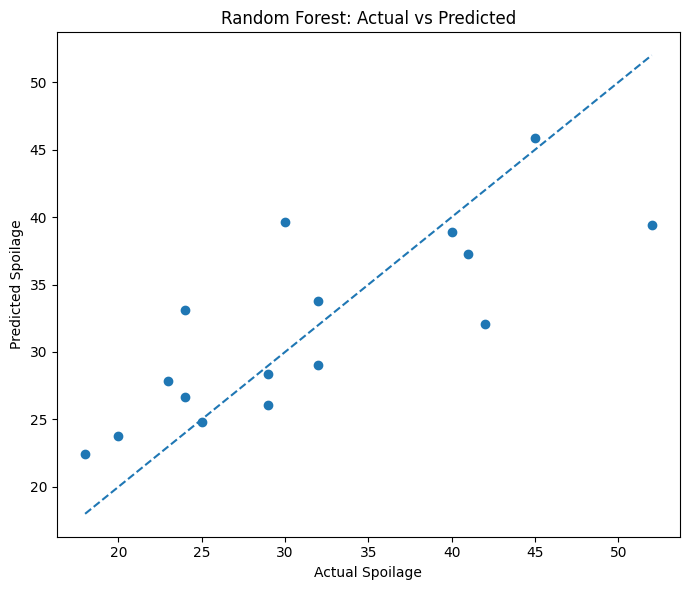

Prediction results and plot saved!


In [15]:

from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import LeaveOneOut, cross_val_predict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

# Simple baseline: predict the training-set mean each time
baseline = DummyRegressor(strategy="mean")

baseline_predictions = cross_val_predict(
    baseline, X, y, cv=LeaveOneOut()
)

# Compare both models
comparison = pd.DataFrame({
    "Model": ["Mean Baseline", "Random Forest"],
    "MAE": [
        mean_absolute_error(y, baseline_predictions),
        mean_absolute_error(y, predictions)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y, baseline_predictions)),
        np.sqrt(mean_squared_error(y, predictions))
    ],
    "R2": [
        r2_score(y, baseline_predictions),
        r2_score(y, predictions)
    ]
})

print("MODEL COMPARISON")
display(comparison.round(3))

# Create organized project result folders
os.makedirs("food-spoilage-prediction/results", exist_ok=True)

# Save actual predictions for reproducibility
results = pd.DataFrame({
    "Actual_Spoilage": y.to_numpy(),
    "Random_Forest_Prediction": predictions,
    "Mean_Baseline_Prediction": baseline_predictions
})

results.to_csv(
    "food-spoilage-prediction/results/predictions.csv",
    index=False
)

# Visualize actual vs predicted values
plt.figure(figsize=(7, 6))
plt.scatter(y, predictions)

lower = min(y.min(), predictions.min())
upper = max(y.max(), predictions.max())
plt.plot([lower, upper], [lower, upper], "--")

plt.xlabel("Actual Spoilage")
plt.ylabel("Predicted Spoilage")
plt.title("Random Forest: Actual vs Predicted")
plt.tight_layout()
plt.savefig(
    "food-spoilage-prediction/results/actual_vs_predicted.png",
    dpi=150
)
plt.show()

print("Prediction results and plot saved!")


In [16]:

import json
import os

project_dir = "food-spoilage-prediction"
results_dir = os.path.join(project_dir, "results")
os.makedirs(results_dir, exist_ok=True)

# Save experiment metrics
metrics = {
    "dataset_rows": int(len(df)),
    "target": "Spoilage",
    "model": "RandomForestRegressor",
    "evaluation": "Leave-One-Out Cross-Validation",
    "mae": round(float(mean_absolute_error(y, predictions)), 3),
    "rmse": round(float(np.sqrt(mean_squared_error(y, predictions))), 3),
    "r2": round(float(r2_score(y, predictions)), 3),
    "note": (
        "Preliminary results on 16 experimental runs. "
        "Not evidence of real-world generalization."
    )
}

with open(
    os.path.join(results_dir, "baseline_metrics.json"),
    "w"
) as f:
    json.dump(metrics, f, indent=4)

print("Experiment metrics saved!")
print(json.dumps(metrics, indent=4))
print("\nProject results folder:", results_dir)


Experiment metrics saved!
{
    "dataset_rows": 16,
    "target": "Spoilage",
    "model": "RandomForestRegressor",
    "evaluation": "Leave-One-Out Cross-Validation",
    "mae": 4.445,
    "rmse": 5.776,
    "r2": 0.627,
    "note": "Preliminary results on 16 experimental runs. Not evidence of real-world generalization."
}

Project results folder: food-spoilage-prediction/results


In [17]:

import os

project_dir = "food-spoilage-prediction"

folders = [
    "data",
    "notebooks",
    "src",
    "results",
    "app",
    "docs"
]

for folder in folders:
    os.makedirs(os.path.join(project_dir, folder), exist_ok=True)

gitignore_content = """__pycache__/
*.py[cod]
.ipynb_checkpoints/
.env
venv/
.venv/
.DS_Store
"""

with open(os.path.join(project_dir, ".gitignore"), "w") as f:
    f.write(gitignore_content)

print("Project structure created!")
for root, dirs, files in os.walk(project_dir):
    dirs[:] = sorted(d for d in dirs if d != "__pycache__")
    level = root.replace(project_dir, "").count(os.sep)
    print("  " * level + os.path.basename(root) + "/")
    for file in sorted(files):
        print("  " * (level + 1) + file)


Project structure created!
food-spoilage-prediction/
  .gitignore
  app/
  data/
  docs/
  notebooks/
  results/
    actual_vs_predicted.png
    baseline_metrics.json
    predictions.csv
  src/


In [18]:

from pathlib import Path

project_dir = Path("food-spoilage-prediction")
project_dir.mkdir(parents=True, exist_ok=True)

readme = """# Food Spoilage Risk Prediction Using Machine Learning

## Overview

This project explores machine-learning methods for predicting recorded food-spoilage values from experimental storage and treatment factors.

The current prototype uses a Random Forest regression model evaluated using Leave-One-Out Cross-Validation (LOOCV).

## Dataset

- Source: Minitab Food Spoilage dataset
- Experimental runs: 16
- Target variable: `Spoilage`
- Input features: `Preservative`, `VacuumPress`, `ContaminationLevel`, `CoolTemp`

The dataset contains experimental runs, not timestamped sensor histories for individual food items.

## Preliminary Results

| Model | MAE | RMSE | R² |
|---|---:|---:|---:|
| Mean Baseline | 8.350 | 10.090 | -0.138 |
| Random Forest | 4.445 | 5.776 | 0.627 |

These results were obtained using Leave-One-Out Cross-Validation on 16 observations. They are preliminary and do not establish performance on new foods or real-world storage conditions.

## Project Structure

```text
food-spoilage-prediction/
├── app/
├── data/
├── docs/
├── notebooks/
├── results/
│   ├── actual_vs_predicted.png
│   ├── baseline_metrics.json
│   └── predictions.csv
├── src/
├── .gitignore
└── README.md
```

## Current Progress

- [x] Dataset loaded and inspected
- [x] Random Forest regression baseline trained
- [x] Leave-One-Out Cross-Validation performed
- [x] Mean baseline comparison completed
- [x] Metrics, predictions and plot saved
- [x] README created
- [ ] Reusable training code
- [ ] Reproducible notebook
- [ ] Additional model evaluation
- [ ] Prediction dashboard
- [ ] Cloud integration

## Results Files

- `results/baseline_metrics.json`: evaluation metrics
- `results/predictions.csv`: actual values and cross-validated predictions
- `results/actual_vs_predicted.png`: prediction visualization

## Limitations

- The dataset contains only 16 experimental observations.
- Evaluation results are uncertain due to the small dataset.
- The current model predicts the recorded `Spoilage` value; it is not a validated food-safety classifier.
- Advanced models, dashboard functionality and cloud integration are planned features and have not yet been implemented.

## Data Attribution

Dataset: Minitab Food Spoilage dataset.

Official source: https://support.minitab.com/en-us/datasets/doe-data-sets/food-spoilage-data/

Check the source's terms and permissions before redistributing the original dataset.

## Disclaimer

This project is an educational machine-learning prototype and is not a certified food-safety system.
"""

(project_dir / "README.md").write_text(readme, encoding="utf-8")

print("README.md created successfully!")
print("Location:", project_dir / "README.md")


README.md created successfully!
Location: food-spoilage-prediction/README.md


In [19]:

from pathlib import Path

project_dir = Path("food-spoilage-prediction")
src_dir = project_dir / "src"
src_dir.mkdir(parents=True, exist_ok=True)

code = '''import json
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import LeaveOneOut, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder


def evaluate_predictions(y_true, y_pred):
    return {
        "mae": round(float(mean_absolute_error(y_true, y_pred)), 3),
        "rmse": round(float(np.sqrt(mean_squared_error(y_true, y_pred))), 3),
        "r2": round(float(r2_score(y_true, y_pred)), 3),
    }


def main():
    project_dir = Path(__file__).resolve().parents[1]
    data_path = project_dir / "data" / "food_spoilage.csv"
    results_dir = project_dir / "results"
    results_dir.mkdir(parents=True, exist_ok=True)

    if not data_path.exists():
        raise FileNotFoundError(
            f"Dataset not found: {data_path}. "
            "Place the prepared dataset at this path."
        )

    df = pd.read_csv(data_path)

    features = [
        "Preservative",
        "VacuumPress",
        "ContaminationLevel",
        "CoolTemp",
    ]
    target = "Spoilage"

    X = df[features]
    y = df[target]

    preprocessor = ColumnTransformer([
        ("preservative", OneHotEncoder(handle_unknown="ignore"),
         ["Preservative"]),
        ("numeric", "passthrough",
         ["VacuumPress", "ContaminationLevel", "CoolTemp"]),
    ])

    models = {
        "Mean Baseline": DummyRegressor(strategy="mean"),
        "Random Forest": RandomForestRegressor(
            n_estimators=100,
            max_depth=3,
            random_state=42,
        ),
    }

    metrics = {
        "dataset_rows": int(len(df)),
        "target": target,
        "evaluation": "Leave-One-Out Cross-Validation",
        "models": {},
        "note": (
            "Preliminary evaluation on a small experimental dataset; "
            "not evidence of real-world generalization."
        ),
    }

    predictions_table = pd.DataFrame({"Actual_Spoilage": y.to_numpy()})

    for name, estimator in models.items():
        model = Pipeline([
            ("preprocessor", preprocessor),
            ("regressor", estimator),
        ])

        predictions = cross_val_predict(
            model, X, y, cv=LeaveOneOut()
        )

        metrics["models"][name] = evaluate_predictions(y, predictions)
        predictions_table[name.replace(" ", "_") + "_Prediction"] = predictions

    predictions_table.to_csv(
        results_dir / "predictions.csv", index=False
    )

    with open(results_dir / "baseline_metrics.json", "w") as f:
        json.dump(metrics, f, indent=4)

    print(json.dumps(metrics, indent=4))


if __name__ == "__main__":
    main()
'''

(src_dir / "train_model.py").write_text(code, encoding="utf-8")

print("Training script created:", src_dir / "train_model.py")


Training script created: food-spoilage-prediction/src/train_model.py


In [20]:

from pathlib import Path

project_dir = Path("food-spoilage-prediction")
data_dir = project_dir / "data"
data_dir.mkdir(parents=True, exist_ok=True)

csv_path = data_dir / "food_spoilage.csv"
df.to_csv(csv_path, index=False)

print("Dataset exported successfully!")
print("File:", csv_path)
print("Rows:", len(df))
print("Columns:", len(df.columns))
display(pd.read_csv(csv_path).head())


Dataset exported successfully!
File: food-spoilage-prediction/data/food_spoilage.csv
Rows: 16
Columns: 10


,StdOrder,RunOrder,CenterPt,Blocks,Preservative,VacuumPress,ContaminationLevel,CoolTemp,Spoilage,Containers
0,1.0,7.0,1.0,1.0,Formula1,5.0,5.0,10.0,20.0,500.0
1,2.0,6.0,1.0,1.0,Formula2,5.0,5.0,10.0,32.0,500.0
2,3.0,9.0,1.0,1.0,Formula1,25.0,5.0,10.0,29.0,500.0
3,4.0,14.0,1.0,1.0,Formula2,25.0,5.0,10.0,42.0,500.0
4,5.0,15.0,1.0,1.0,Formula1,5.0,50.0,10.0,24.0,500.0


In [21]:

from pathlib import Path

project_dir = Path("food-spoilage-prediction")

requirements = """pandas
numpy
scikit-learn
matplotlib
"""

requirements_path = project_dir / "requirements.txt"
requirements_path.write_text(requirements, encoding="utf-8")

print("requirements.txt created!")
print(requirements_path.read_text())


requirements.txt created!
pandas
numpy
scikit-learn
matplotlib



In [22]:

%cd /content/food-spoilage-prediction
!python src/train_model.py


/content/food-spoilage-prediction
{
    "dataset_rows": 16,
    "target": "Spoilage",
    "evaluation": "Leave-One-Out Cross-Validation",
    "models": {
        "Mean Baseline": {
            "mae": 8.35,
            "rmse": 10.09,
            "r2": -0.138
        },
        "Random Forest": {
            "mae": 4.445,
            "rmse": 5.776,
            "r2": 0.627
        }
    },
    "note": "Preliminary evaluation on a small experimental dataset; not evidence of real-world generalization."
}
